# Unit 2: statistics, probability and exploratory evidence

This extends the Unit 1 credit card analysis for Muhammad Asim. Unit 1 notebooks 01–04 are retained as historical work; this notebook is self-contained from the raw file.

**Audience:** a retention analyst deciding which activity measures deserve further investigation. **Purpose:** quantify recorded attrition and assess three exploratory associations. The snapshot cannot establish which behaviour precedes departure or whether an intervention would work.

## Structured plan and business requirements (LO2.1, LO3.3)

1. Validate and clean the raw customer snapshot using reusable functions.
2. Describe the customer population and uncertainty around observed attrition (BR1).
3. State and test three exploratory hypotheses, report effect sizes and multiple-test adjustment (BR2).
4. Compare activity and product holdings visually (BR2/BR3).
5. Fit and evaluate a classification prototype in notebook 06 (BR4).
6. Present interactive historical segments in the Streamlit dashboard (BR3).
7. Evaluate limitations and record reproducible AI assistance and technical lessons.

The task board and criterion map are in `docs/PROJECT_PLAN.md` and `docs/ASSESSMENT_MAP.md`.

In [1]:
# Resolve paths when launched from either the root or notebook directory.
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import extract_transform_load, OUTPUT, FEATURES
from src.statistics import wilson_interval, segment_summary, test_hypotheses
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False, 'axes.spines.right': False})
df, quality = extract_transform_load()
print(f'{len(df):,} customer snapshots; {df.Churn.sum():,} attrited ({df.Churn.mean():.2%}).')

10,127 customer snapshots; 1,627 attrited (16.07%).


## Reproducible ETL and integrity (LO2.1, LO3.1)

`src/data.py` separates validation, transformation and output. Raw data remains unchanged. Validation rejects duplicate/missing identifiers, invalid target labels, missing required fields, nonfinite/negative numerical values, impossible utilisation and fractional counts. A SHA-256 digest records source identity.

The whitelist excludes stored Naive Bayes predictions, the customer identifier and redundant open-to-buy field. Unknown demographic values become missing, without imputation or row deletion. Failure to detect a missingness association does **not** prove missingness is random. Outliers remain because plausible extremes carry information; contact-count tails need small-sample caution. Tenure is retained for historical inspection but excluded from modelling because of a concentration at 36 months of uncertain origin.

In [2]:
# Inspect the validation record and resulting missingness.
display(pd.Series(quality, name='Value'))
display(df.isna().sum().rename('Missing customers').to_frame())

rows_raw                                                      10127
rows_clean                                                    10127
duplicate_ids                                                     0
churn_count                                                    1627
churn_rate                                                  0.16066
missing_values    {'Attrition_Flag': 0, 'Customer_Age': 0, 'Gend...
model_features    [Total_Relationship_Count, Months_Inactive_12_...
excluded          [CLIENTNUM, Attrition_Flag, Churn, Avg_Open_To...
source_sha256     c91b525a2a6755a1b0b80dad1d0d008ca97ec4df34552c...
Name: Value, dtype: object

,Missing customers
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,1519
Marital_Status,749
Income_Category,1112
Card_Category,0
Months_on_book,0
Total_Relationship_Count,0


## Core statistical principles (LO1.1 and LO1.2)

- **Mean:** arithmetic average; sensitive to a few large transaction amounts. Useful for portfolio totals and expected workloads.
- **Median:** the middle ordered value; more robust for skewed balances and spending.
- **Variance:** average squared distance from the mean; sample variance uses n−1. **Standard deviation** is its square root and uses the original units.
- **Probability:** the observed fraction attrited estimates P(attrition) for this snapshot. P(attrition | product count) conditions on a segment and uses that segment's denominator. Independence would imply the conditional rates match the unconditional rate.
- **Sampling uncertainty:** Wilson 95% intervals are preferable to a normal approximation near zero or one. The repeated-sampling interpretation is that about 95% of intervals constructed this way cover a fixed population proportion under independent sampling. The file is not proven to be a representative random sample; these intervals do not account for selection bias or future drift.
- **Hypothesis testing:** compare a statistic to its distribution under a null hypothesis. A p-value is not the probability the null is true. Alpha = 0.05 is specified before the Unit 2 tests. Statistical significance alone does not establish practical value or causation.

No normality assumption is imposed on strongly skewed activity variables. Mann–Whitney tests distributional differences; it is not a pure median test unless distributions have the same shape. Rank-biserial effect sizes give signed separation of ranks. Chi-square tests association between product count and outcome; Cramer's V expresses strength on a 0–1 scale.

In [3]:
# Compare sample mean, median, variance and standard deviation by observed status.
descriptive = df.groupby('Attrition_Flag')[['Total_Trans_Ct','Total_Trans_Amt','Total_Revolving_Bal']].agg(['count','mean','median','var','std'])
display(descriptive.round(3))
low, high = wilson_interval(int(df.Churn.sum()), len(df))
print(f'P(attrition) = {df.Churn.mean():.4f}; Wilson 95% interval [{low:.4f}, {high:.4f}].')
display(segment_summary(df,'Total_Relationship_Count'))

Total_Trans_Ct                                  \
                           count    mean median      var     std   
Attrition_Flag                                                     
Attrited Customer           1627  44.934   43.0  212.239  14.568   
Existing Customer           8500  68.673   71.0  525.281  22.919   

                  Total_Trans_Amt                                            \
                            count      mean  median           var       std   
Attrition_Flag                                                                
Attrited Customer            1627  3095.026  2329.0  5.327915e+06  2308.228   
Existing Customer            8500  4654.656  4100.0  1.233957e+07  3512.773   

                  Total_Revolving_Bal                                         
                                count      mean  median         var      std  
Attrition_Flag                                                                
Attrited Customer                1627   672.823     0.0  848951.391  921.386  
Existing Customer                8500  1256.604  1364.0  574178.021  757.745

P(attrition) = 0.1607; Wilson 95% interval [0.1536, 0.1679].


,Total_Relationship_Count,customers,churned,churn_rate,ci_lower,ci_upper
0,1,910,233,0.256044,0.228754,0.285385
1,2,1243,346,0.278359,0.254155,0.303928
2,3,2305,400,0.173536,0.158622,0.189536
3,4,1912,225,0.117678,0.103995,0.132894
4,5,1891,227,0.120042,0.106158,0.135467
5,6,1866,196,0.105038,0.091928,0.119770


## Three exploratory hypotheses (LO3.1)

These follow Unit 1 observations and are therefore **exploratory**, not a new independent confirmatory study.

| Hypothesis | Null hypothesis | Alternative and business question | Method |
|---|---|---|---|
| H1 | Transaction-count distributions are equal between status groups | They differ; does lower observed activity accompany attrition? | Two-sided Mann–Whitney U, rank-biserial effect |
| H2 | Q4/Q1 transaction-count ratio distributions are equal | They differ; is the observed activity change informative? | Two-sided Mann–Whitney U, rank-biserial effect |
| H3 | Product count and attrition are independent | They are associated; which portfolios show greater attrition? | Chi-square and Cramer's V |

Holm correction controls family-wise error across these three tests. It does not remove the exploratory bias from earlier dataset inspection. Rows represent distinct customers, supporting independence between observations; dependence through households/bank processes is unmeasured. We inspect the smallest expected chi-square count before using its asymptotic approximation.

In [4]:
# Export all test statistics and adjusted p-values for auditability.
hypotheses = test_hypotheses(df)
hypotheses.to_csv(OUTPUT / 'hypotheses.csv', index=False)
display(hypotheses)
print('A displayed p=0 is numerical underflow, not literally zero; report p < 0.001.')
print('Minimum expected H3 count:', hypotheses.loc[hypotheses.hypothesis.eq('H3'),'minimum_expected_count'].iloc[0])

,hypothesis,variable,test,statistic,p_value,effect,effect_measure,churn_median,retained_median,minimum_expected_count,p_holm,reject_at_0_05
0,H1,Total_Trans_Ct,Mann-Whitney U,2.826174e+06,0.000000e+00,-0.591283,rank-biserial (churn minus retained),43.000,71.000,NaN,0.000000e+00,True
1,H2,Total_Ct_Chng_Q4_Q1,Mann-Whitney U,3.522217e+06,1.908241e-216,-0.490623,rank-biserial (churn minus retained),0.531,0.721,NaN,3.816481e-216,True
2,H3,Total_Relationship_Count,Chi-square independence,2.840675e+02,2.661050e-59,0.167483,Cramer's V,NaN,NaN,146.200257,2.661050e-59,True


A displayed p=0 is numerical underflow, not literally zero; report p < 0.001.
Minimum expected H3 count: 146.2002567394095


### Interpretation and practical limits

H1 and H2 show lower activity and count-change ratios in the attrited group, with substantial negative rank-biserial effects. H3 rejects independence but has a smaller Cramer's V. A significant omnibus product-count test does not prove every adjacent product category differs. Segmented rates provide descriptive context only; an experiment is needed to estimate the benefit of selling a third product.

The large sample allows very small p-values. Effect sizes and confidence intervals are more useful for judging the strength and uncertainty of these associations. None of these tests measures lead time.

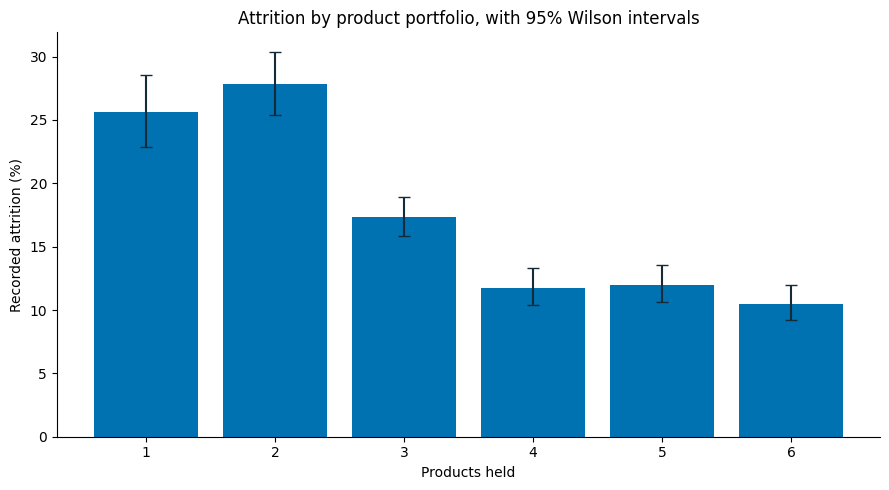

In [5]:
# Wilson error bars make small-segment uncertainty visible.
summary = segment_summary(df,'Total_Relationship_Count')
fig, ax = plt.subplots()
ax.bar(summary.Total_Relationship_Count, summary.churn_rate*100, color='#0072B2')
ax.errorbar(summary.Total_Relationship_Count, summary.churn_rate*100,
 yerr=[(summary.churn_rate-summary.ci_lower)*100,(summary.ci_upper-summary.churn_rate)*100],fmt='none',ecolor='#162B3A',capsize=4)
ax.set(xlabel='Products held',ylabel='Recorded attrition (%)',title='Attrition by product portfolio, with 95% Wilson intervals')
fig.tight_layout()
fig.savefig(OUTPUT/'product_rates.png',dpi=160)
plt.show()

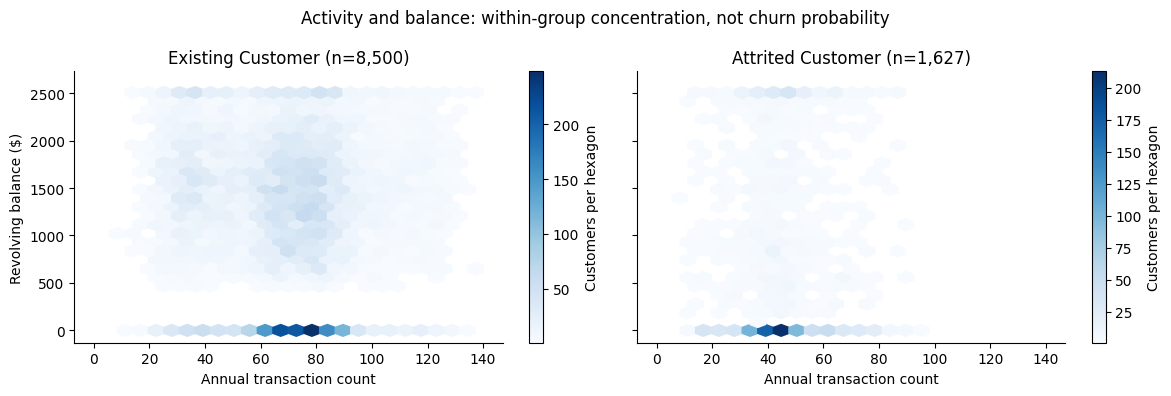

In [6]:
# Hexbin counts avoid hiding dense clusters beneath overlapping points.
fig, axes = plt.subplots(1,2,figsize=(12,4),sharex=True,sharey=True)
for ax, status in zip(axes,['Existing Customer','Attrited Customer']):
 group = df[df.Attrition_Flag.eq(status)]
 artist = ax.hexbin(group.Total_Trans_Ct,group.Total_Revolving_Bal,gridsize=25,mincnt=1,cmap='Blues',extent=(0,140,0,2600))
 ax.set(title=f'{status} (n={len(group):,})',xlabel='Annual transaction count')
 fig.colorbar(artist,ax=ax,label='Customers per hexagon')
axes[0].set_ylabel('Revolving balance ($)')
fig.suptitle('Activity and balance: within-group concentration, not churn probability')
fig.tight_layout()
fig.savefig(OUTPUT/'activity_hexbin.png',dpi=160)
plt.show()

## Evaluation and next step (LO3.2)

The bar chart maps product holdings to BR2 and includes uncertainty; the hexbin plot maps activity/balance to BR2 while avoiding scatter overplotting. Colour bars are counts with separate scales, so panel intensities cannot be read as comparative churn risk. Neither graphic depends on colour alone: labels identify the groups.

The evidence supports investigating activity-led retention, with human review. Snapshot fields may overlap closure and demographics may be missing for systematic reasons. Avoid claims that inactivity happens first, repeated contacts cause departure or more products prevent it. Notebook 06 evaluates whether these features can classify the recorded status, using a train/validation/test protocol.